# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [4]:
!pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 10.5 MB/s  0:00:00 eta 0:00:01


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

In [26]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [ ]:
class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images.transpose(0,3,1,2).astype('float32')
        self.labels = labels.squeeze().astype('int64')
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self,id):
        img = self.images[id]
        label = self.labels[id]

        if self.transform:
            img = self.transform(img)

        return torch.tensor(img, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

Kształt X_train: (11959, 28, 28, 3)
Kształt y_train: (11959, 1)


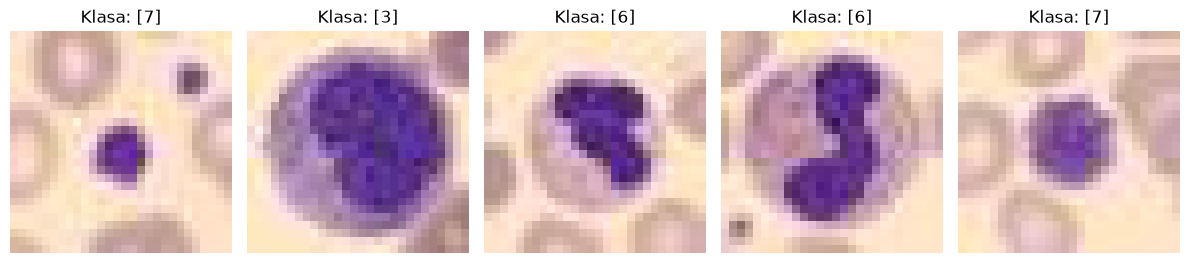

In [27]:
X_train = data['train_images']
y_train = data['train_labels']
X_val = data['val_images']
y_val = data['val_labels']
X_test = data['test_images']
y_test = data['test_labels']

print('Kształt X_train:', X_train.shape)
print('Kształt y_train:', y_train.shape)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
  img = X_train[i]
  ax.imshow(img)
  ax.axis('off')

  label = y_train[i]
  ax.set_title(f'Klasa: {label}')

plt.tight_layout()
plt.show()

In [28]:
classes, counts = np.unique(y_train, return_counts=True)
for cls, count in zip(classes, counts):
  print(f'Klasa {cls}: {count} próbek')

print("Typ danych: ",X_train.dtype)
print("Zakres pikseli: ",X_train.min(),"-",X_train.max())
print("Wartości NaN: ", np.isnan(X_train).sum())
print("Kanały:", X_train.shape[-1])

print(
    'Czy każdy obraz ma wymiar 28x28x3?',
    all(img.shape == (28, 28, 3) for img in X_train),
)


Klasa 0: 852 próbek
Klasa 1: 2181 próbek
Klasa 2: 1085 próbek
Klasa 3: 2026 próbek
Klasa 4: 849 próbek
Klasa 5: 993 próbek
Klasa 6: 2330 próbek
Klasa 7: 1643 próbek
Typ danych:  uint8
Zakres pikseli:  0 - 255
Wartości NaN:  0
Kanały: 3
Czy każdy obraz ma wymiar 28x28x3? True


In [ ]:
m = X_train.mean(axis=(0,1,2))
s = X_train.std(axis=(0,1,2))

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ToTensor(),
    transforms.Normalize(mean=[m[0],m[1],m[2]], std=[s[0],s[1],s[2]])
])


## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.